# EDIT/EXPERIMENTAL Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  Joanan van Loo

**Title of the experiment:**  From Current to Constant: Determining the Boltzmann Constant Using a Silicon Diode

**Starting date:**  11-11-2026

**Expected enddate:**  23-11-2026

**Partner:**  Annefleur Regeling

**Goal of the experiment:**  Determining the Boltzmann constant

**Research question:**  How can the boltzmann constant be approached using the (I,V) characteristics of a diode

**Expectations or Hypothesis:**  We expect the theory delivers and provides us a storng result

**Desired accuracy:**  1%




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

### weerstands metingen:

Accuracy± (% of Reading + % of Range)

| Range | Uncertainty at 23 ± 5 °C | Temperature coefficient (outside 23 ± 5 °C) |
|---|---|---|
| 200 Ω | ±(0.030 + 0.005) | ±(0.0030 + 0.0006) per °C |
| 2 kΩ | ±(0.020 + 0.003) | ±(0.0030 + 0.0005) per °C |
| 20 kΩ | ±(0.020 + 0.003) | ±(0.0030 + 0.0005) per °C |
Reference:
https://siglentna.com/wp-content/uploads/dlm_uploads/2023/04/SDM3055_Datasheet_E04A.pdf

R_1: 99927 ± 3  <!--2.59854-->

R_2: 468.26 ± 0.2  <!--0.15362-->

R_3: 100.34 ± 0.04  <!--100.34 ± 0.0401008-->

In [2]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
R_1=9.9927e3
R_2=468.26 
R_3=100.336 

U_1=np.array([0.042e-3,0.071e-3,0.153e-3,0.439e-3,1.1074e-3,2.643e-3,5.965e-3,
            12.567e-3,24.038e-3,41.210e-3,63.703e-3,90.445e-3,120.422e-3,152.635e-3,
            186.805e-3,0.22222,0.25868,0.29611,0.33403,0.37271,0.41180,0.45115,
            0.49100,0.53111,0.57136,0.65266,0.73476,0.81722,0.90029,0.98351,
            1.06735,1.15130,1.23554,1.31995,1.40457
            ])
U_bron=np.array([0.25,0.34,0.49,0.74,0.99,1.24,1.49,1.74,1.99,2.24,2.49,2.74,2.99,
                 3.24,3.49,3.74,3.99,4.24,4.49,4.74,4.99,5.24,5.49,5.74,5.99,6.49,
                 6.99,7.49,7.99,8.49,8.99,9.49,9.99,10.49,10.99
            ])

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


Text(0.5, 0, 'Voltage Diode $(U)$')

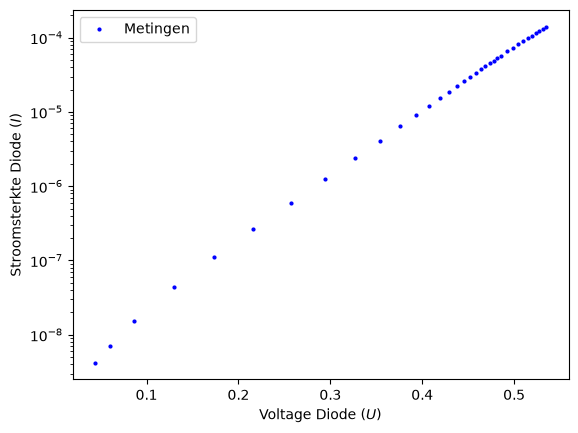

In [3]:
U_3=R_3/(R_2+R_3)*U_bron
U_diode=U_3-U_1
I_diode=U_1/R_1

plt.figure()
plt.yscale('log')
plt.plot(U_diode,I_diode,'b.',markersize=4,label='Metingen')
plt.legend()
plt.ylabel('Stroomsterkte Diode $(I)$')
plt.xlabel('Voltage Diode $(U)$')

### final Fit and found values

I_0 = 3.49e-09 ± 2e-11 A)
(just to test) a  = 20.00 ± 0.02 1/V
k_B = 1.371e-23 ± 7e-25 J/K   (literatuur: 1.380649e-23)
Temperatuur = 2.92e+02 ± 5e-01 K


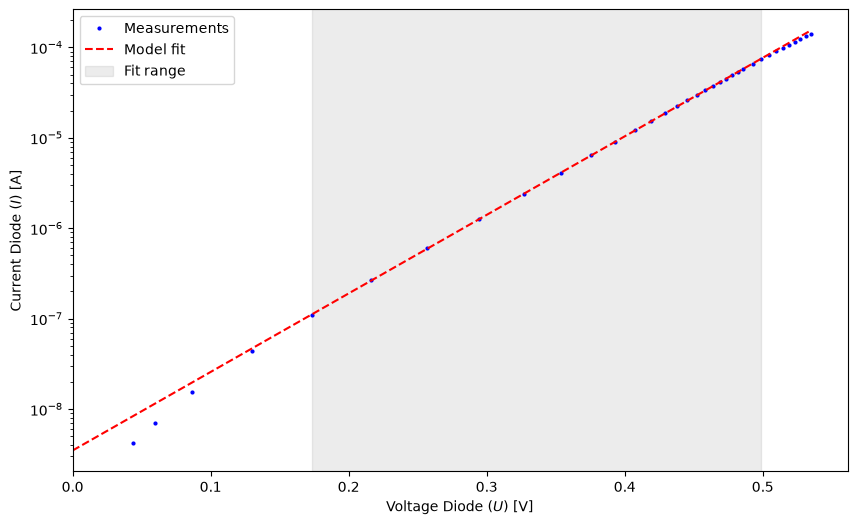

N_sigma heeft de waarde: 0.13821070229710583
Conclusie: de waarden komen goed overeen.


In [36]:
q  = 1.602176634e-19     # C, sign is anders dan voorbereiding, schilt een min factor in de berekening
T  = 19+273.15               # K, kamertemp, assumed
T_unc = 0.5              # K, onzekerheid in T, assumed
n  = 2.0                 # aangenomen idealiteitsfactor silicum uit voorbereiding
n_unc = 0.1

# Verwerking
U_3 = R_3/(R_2+R_3)*U_bron
U_diode = U_3 - U_1
I_diode = U_1/R_1

# Fitbereik: weg van ruis (laag) en serieweerstand (hoog), zodat we alleen het lineare deel bekijken, waardoor we de constante kunnen berekenen
mask = (U_diode > 0.14) & (U_diode < 0.5)
U_diode_mask, I_diode_mask = U_diode[mask], I_diode[mask]

# model in log vorm, zodat alle decaden even zwaar meetellen
# vrije parameters: ln(I0) en a = q/(n kB T)
def model(U, lnI_0, a):
    return lnI_0 + np.log(np.exp(a*U)) #ln is makkelijker met terug converten

val2, cov2 = curve_fit(model, U_diode_mask, np.log(I_diode_mask), p0=[np.log(1e-9), 20.0])
lnI_0, a = val2
lnI_0_unc, a_unc = np.sqrt(np.diag(cov2))
I_0 = np.exp(lnI_0)
I_0_unc=np.exp(lnI_0_unc)
I_0_unc=I_0-I_0/I_0_unc

# Boltzmann-constante
k_B  = q/(a*n*T)
k_B_unc = k_B*np.sqrt((a_unc/a)**2 + (n_unc/n)**2 + (T_unc/T)**2)

print(f"I_0 = {I_0:.2e} ± {I_0_unc:.0e} A)")
print(f"(just to test) a  = {a:.2f} ± {a_unc:.2f} 1/V")
print(f"k_B = {k_B:.3e} ± {k_B_unc:.0e} J/K   (literatuur: 1.380649e-23)")
print(f"Temperatuur = {T:.2e} ± {T_unc:.0e} K")

# quickie test voor strijdigheid
#print(k_B,'+/-',k_B_unc,k_B+k_B_unc)

# Plot
plt.figure(figsize=(10,6))

plt.plot(U_diode, I_diode, 'b.', markersize=4, label='Measurements')
#linspace for smooth line
Ufit = np.linspace(0,max(U_diode), 200)
plt.plot(Ufit, I_0*(np.exp(a*Ufit)), 'r--', label='Model fit')

#plotting I_0, only for debug
    #plt.plot(0,I_0,'k.',markersize=10,label='$I_0$')
    #plt.axhline(I_0,linewidth=1,label='$I_0$')

#layout and info of figure
plt.yscale('log')
plt.axvspan(min(U_diode_mask), max(U_diode_mask), color='gray', alpha=0.15, label='Fit range')
plt.xlabel('Voltage Diode $(U)$ [V]')
plt.ylabel('Current Diode $(I)$ [A]')
plt.xlim(0,max(U_diode)*1.05)
plt.legend()
#savefig
plt.savefig('Boltzman_constante_plot_fit.png',dpi=330)
#plt.grid(True)
plt.show()

#strijdigheids analyse
delta_k_B=1.380649e-23-k_B
#boltzman referentie is gedefinieerd dus geen uncertainty combined
N_sigma=delta_k_B/k_B_unc
print('N_sigma heeft de waarde:', N_sigma)
if N_sigma < 1:
    print("Conclusie: de waarden komen goed overeen.")

elif N_sigma < 2:
    print("Conclusie: de waarden komen redelijk overeen.")

else:
    print("Conclusie: het gemeten resultaat wijkt af van de vastgestelde waarde.")

## random bs, testing

In [95]:
#error V diode
#mask voor opsplitsing van de onzekerheid ivm range onzekerheid
mask_2v  = U_1 >= 0.2      # 2 V range
mask_02v = U_1 <  0.2      # 200 mV range

R_1_unc=2.59854 #see table above for source of all 3
R_2_unc=0.15362
R_3_unc=0.0401008
#zie bibliography report voor source van onzekerheid formules
U_bron_unc=0.7/100*U_bron+0.01 #reading and digit from 3.5 digit dmm
U_1_unc=0.015/100*U_1[mask_02v] + 0.004/100*0.2 #reading and range from 5.5dmm
U_1_unc=np.append(U_1_unc,0.015/100*U_1[mask_2v] + 0.003/100*2)

#hellish approach to calculating U_3_unc
dU3_dR2 = -R_3*U_bron/(R_2+R_3)**2 #all parts need to be calculated ''seperately''
dU3_dR3 =  R_2*U_bron/(R_2+R_3)**2
dU3_dUb =  R_3/(R_2+R_3)

U_3_unc = np.sqrt((dU3_dR2*R_2_unc)**2
                + (dU3_dR3*R_3_unc)**2
                + (dU3_dUb*U_bron_unc)**2)
#final uncertainties used in curvefit(I_D) and/or errorbar plot (U_D)
U_diode_unc=np.sqrt(U_1_unc**2+U_3_unc**2)
I_diode_unc=abs(I_diode)*np.sqrt((U_1_unc/U_1)**2+(R_1_unc/R_1)**2)
#print(U_diode_unc)
#print(I_diode_unc)

I_0 = 3.49e-09 ± 3e-11 A)
(just to test) a  = 19.99 ± 0.02 1/V
k_B = 1.371e-23 ± 6.86218e-25 J/K   (literatuur: 1.380649e-23)
Temperatuur = 2.92e+02 ± 5e-01 K


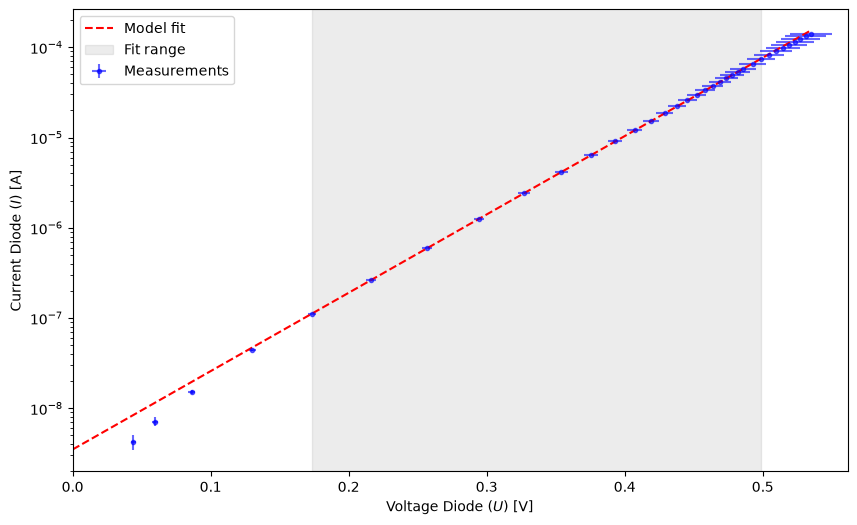

In [96]:
q  = 1.602176634e-19     # C, sign is anders dan voorbereiding, schilt een min factor in de berekening
T  = 19+273.15               # K, kamertemp, assumed
T_unc = 0.5              # K, onzekerheid in T, assumed
n  = 2.0                 # aangenomen idealiteitsfactor silicon uit voorbereiding
n_unc = 0.1

# Verwerking
U_3 = R_3/(R_2+R_3)*U_bron
U_diode = U_3 - U_1
I_diode = U_1/R_1

# Fitbereik: weg van ruis (laag) en serieweerstand (hoog), zodat we alleen het lineare deel bekijken, waardoor we de constante kunnen berekenen
mask = (U_diode > 0.14) & (U_diode < 0.5)
U_diode_mask, I_diode_mask, I_diode_unc_mask= U_diode[mask], I_diode[mask],I_diode_unc[mask]

# model in log vorm, zodat alle decaden even zwaar meetellen
# vrije parameters: ln(I0) en a = q/(n kB T)
def model(U, lnI_0, a):
    return lnI_0 + np.log(np.exp(a*U)) #ln is makkelijker met terug converten
#verwerking van de waardes gegeven door de curve-fit
val2, cov2 = curve_fit(model, U_diode_mask, np.log(I_diode_mask),sigma=np.log(I_diode_unc_mask), p0=[np.log(1e-9), 20.0])
lnI_0, a = val2
lnI_0_unc, a_unc = np.sqrt(np.diag(cov2))
I_0 = np.exp(lnI_0)
I_0_unc=np.exp(lnI_0_unc)
I_0_unc=I_0-I_0/I_0_unc #zonder deze lijn is I_0 een percentage error van de originele

# Boltzmann-constante berekening en de onzekerheid ervan
k_B  = q/(a*n*T)
k_B_unc = k_B*np.sqrt((a_unc/a)**2 + (n_unc/n)**2 + (T_unc/T)**2)

print(f"I_0 = {I_0:.2e} ± {I_0_unc:.0e} A)")
print(f"(just to test) a  = {a:.2f} ± {a_unc:.2f} 1/V")
print(f"k_B = {k_B:.3e} ± {k_B_unc:.5e} J/K   (literatuur: 1.380649e-23)")
print(f"Temperatuur = {T:.2e} ± {T_unc:.0e} K")


# Plot
plt.figure(figsize=(10,6))
#errorbar plot van raw data
plt.errorbar(U_diode, I_diode,yerr=(I_diode_unc),xerr=U_diode_unc,color='blue',label='Measurements',alpha=0.6,fmt=".")
#linspace for smooth fitline
Ufit = np.linspace(0,max(U_diode), 200)
plt.plot(Ufit, I_0*(np.exp(a*Ufit)), 'r--', label='Model fit')

#layout and info of figure
plt.yscale('log')
plt.axvspan(min(U_diode_mask), max(U_diode_mask), color='gray', alpha=0.15, label='Fit range')
plt.xlabel('Voltage Diode $(U)$ [V]')
plt.ylabel('Current Diode $(I)$ [A]')
plt.xlim(0,max(U_diode)*1.05)
plt.legend()
#save the figure
plt.savefig('Boltzman_constante_plot_fit.png',dpi=330)
#plt.grid(True)
plt.show()

In [87]:
#strijdigheids analyse
delta_k_B=1.380649e-23-k_B
#boltzman referentie is gedefinieerd dus geen uncertainty combined
N_sigma=delta_k_B/k_B_unc
print('N_sigma heeft de waarde:', N_sigma)
if N_sigma < 1:
    print("Conclusie: de waarden komen goed overeen.")

elif N_sigma < 2:
    print("Conclusie: de waarden komen redelijk overeen.")

else:
    print("Conclusie: het gemeten resultaat wijkt af van de vastgestelde waarde.")

N_sigma heeft de waarde: 0.1354798390411164
Conclusie: de waarden komen goed overeen.


#### testen of ''linear'' fit zelfde I_0 geeft, aka k_b ingevuld en alleen naar I_0 zoeken met model dat sws linear is in de log schaal
dit is een dubbelcheck of code hierboven klopt. dit doet het, je kunt deze code dus negeren
heb in plot hierboven getest, als in het model functie de -1 wordt weggehaald zal de functie linear lopen

code hieronder geeft gewenste I_0 waarde, dus mn dubbelcheck of de code hierboven goed is werkt


i think log? [-19.47473635] +/- [0.00140848]
extracted from log?, I_0: [3.48521415e-09] +/- [4.90540702e-12]


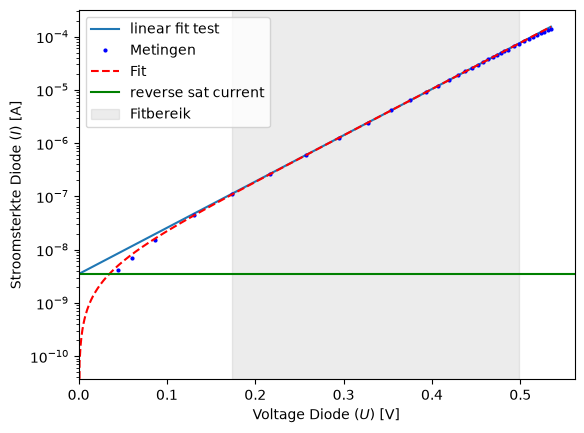

In [33]:
def functiontest(U_diode,a):
    return a+np.log(np.e)*((q*U_diode)/(n*k_B*T))

valtest,covtest=curve_fit(functiontest,U_diode_mask,np.log(I_diode_mask),p0=[np.log(1e-9)])
a_val=valtest
a_val_unc=np.sqrt(np.diag(covtest))
print('i think log?',a_val,'+/-',a_val_unc)
a_val=np.exp(a_val)
a_val_unc=np.exp(a_val_unc)
a_val_unc=a_val-a_val/a_val_unc
print('extracted from log?, I_0:',a_val,'+/-',a_val_unc)

plt.figure()
#plot linear fit
#plt.plot(Ufit,functiontest(Ufit,a_val),label='linear fit test')
plt.plot(Ufit,a_val*(np.exp((q*Ufit)/(n*k_B*T))), label='linear fit test')

plt.plot(U_diode, I_diode, 'b.', markersize=4, label='Metingen')
#linspace for smooth line
Ufit = np.linspace(0,max(U_diode), 500)
plt.plot(Ufit, I_0*(np.exp(a*Ufit)-1), 'r--', label='Fit')
plt.axhline(3.48521415e-09,color='green',label='reverse sat current')
plt.yscale('log')
plt.axvspan(min(U_diode_mask), max(U_diode_mask), color='gray', alpha=0.15, label='Fitbereik')
plt.xlabel('Voltage Diode $(U)$ [V]')
plt.ylabel('Stroomsterkte Diode $(I)$ [A]')
plt.xlim(0,max(U_diode)*1.05)
plt.legend()
plt.show()

**Describing the pattern in the processed data:**  


**Notes:**  sperstroom is nooit direct gemeten dus hebben dit gedaan met de curve fit in log vorm aangezien het dan gewoon een losse y-as-verplaatsende factor is. voor vervolg onderzoek zal dit moeten worden gemeten voor een betrouwbaarder resultaat. verder zit er een afwijking in onze boltzman constante dus zal de idealiteits factor moet worden nagekeken aangezien het mischien een systematische fout kan zijn in ons specifieke resistor bord.

# Discussion

According to \cite{pols_notebook6} this value is well in agreement with the literary value, because $0.14\ll2$, meaning our value deviates $0.14\sigma$ from the literary definition of $k_B$.

The value for $k_B$ even though it may not conflict is not very precise, nor accurate. The reasons for this lack are intertwined. The values used to finally compute $k_B$ were $q$,$n$, and $T$. $q$ is considered defined, which leaves $n$ and $T$ as cause for our lack. $T$ is a presumed value which inherently brings about a chance of imprecision.
\\

However, we believe the biggest cause of both imprecision and inaccuracy to be from the ideality factor $n=2.0\pm0.1$. 

As reason for the inaccuracy we present;
the ratio between the uncertainty divided by the value of $n$ is around 5 and 50 times bigger than $T$ and $a$ from \ref{eq:k_B_calc} respectively. Meaning the inaccuracy caused by $n$ dominates our uncertainty in $k_B$.

Finally, as reason for the imprecision;
a difference in around $0.4\%$ of the value for $n$ would mean our value for $k_B$ would be completely accurate. Deferring the temperature by this $0.4\%$ is highly insensible since we used Kelvin and would mean our environment exceed the plausible temperature range. 

Thus this elimination process presents us with many a possibility for further research. 
These include incorporating the ideality factor as free variable in the fit, or externally computing the ideality factor for this specific diode. However do not forget, proper measurement of the environmental temperature at our setup should also be conducted in further research.

# Conclusion

Fout in idealiteits factor? of meetfouten, iets moet de afwijkende boltzman constante uitleggen

To summarize, we determined $k_B$ from the (I,V) characteristics of a silicon diode. Using a voltage divider along with two DMM's. The current rises exponentially and follows the tweaked theoretical model \ref{eq:data_to_current} we fitted over our measurements. We find $k_B=(1.371\pm0.07)\cdot10^{-23}$J/K and $I_0=(3.49\pm 0.02)\cdot10^{-9}$A, through our fit. This finding is consistent with the literature value of $k_B$ since a conflict analysis provides $N_{\sigma}=0.14$. 
The result is limited mainly by the ideality factor $n$ and possibly temperature $T$. 
\\
With inaccuracies caused by almost wholly by $n$, and imprecision very likely too, further research can be conducted. Where measuring $n$ and $T$ is done directly with proper equipment and external experiments. This would reduce the uncertainty and increase precision greatly. 

# Additional notes, remarks, explanations, thoughts etc